# Customer Churn Prediction

- **Subject:** Artificial Intelligence, Final Project (Question 1)
- **Batch:** 3
- **Name:** Muhammad Faizan
- **Instructor:** Akbar Ali
- **Organization:** Hunarmand Punjab

Churn means a customer leaves a service. A company loses less money if it can find these customers early and offer them something to stay.

In this project I use data from a telecom company to predict if a customer will churn (Yes or No). This is a **classification** problem because the answer is a category, not a number. I train two models, Logistic Regression and KNN, and compare them.

## 1. Import libraries

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# all charts and tables are saved in this folder
os.makedirs("outputs", exist_ok=True)

## 2. Load the dataset

I use the IBM Telco Customer Churn dataset. Each row is one customer and the `Churn` column tells us if they left. If the CSV is not in the `data` folder (for example on Google Colab), it is loaded from the internet.

In [2]:
file_path = "data/Telco-Customer-Churn.csv"
if not os.path.exists(file_path):
    file_path = "https://cdn.jsdelivr.net/gh/IBM/telco-customer-churn-on-icp4d@master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Exploratory Data Analysis (EDA)

Before training any model I want to understand the data.

### How many customers churned?

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


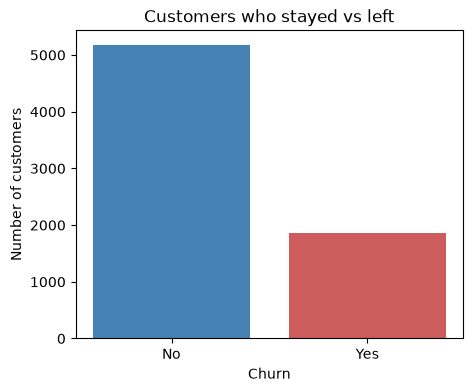

In [4]:
churn_counts = df["Churn"].value_counts()
churn_percent = df["Churn"].value_counts(normalize=True) * 100

print(churn_counts)
print(churn_percent.round(2))

plt.figure(figsize=(5, 4))
plt.bar(churn_counts.index, churn_counts.values, color=["steelblue", "indianred"])
plt.title("Customers who stayed vs left")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.savefig("outputs/churn_count.png", bbox_inches="tight")
plt.show()

Most customers did not churn, so the classes are **imbalanced**. This matters later: a model that always says "No" would still get a high accuracy while finding zero churners. That is why I do not judge the models on accuracy alone.

### Does the contract type matter?

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


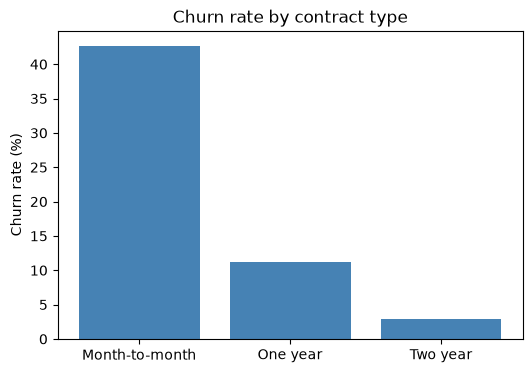

In [5]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)
print(contract_churn.round(1))

plt.figure(figsize=(6, 4))
plt.bar(contract_churn.index, contract_churn.values, color="steelblue")
plt.title("Churn rate by contract type")
plt.ylabel("Churn rate (%)")
plt.savefig("outputs/churn_by_contract.png", bbox_inches="tight")
plt.show()

Contract type makes a very big difference. 42.7% of month-to-month customers left, compared to only 2.8% on a two year contract. A customer on a monthly contract can leave at any time with no penalty.

### Do new customers leave more?

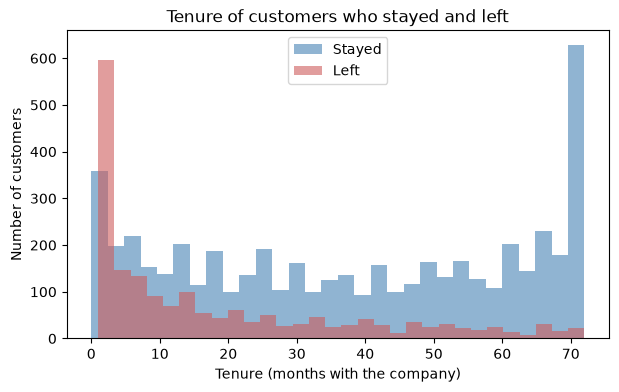

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [6]:
plt.figure(figsize=(7, 4))
plt.hist(df[df["Churn"] == "No"]["tenure"], bins=30, alpha=0.6, label="Stayed", color="steelblue")
plt.hist(df[df["Churn"] == "Yes"]["tenure"], bins=30, alpha=0.6, label="Left", color="indianred")
plt.title("Tenure of customers who stayed and left")
plt.xlabel("Tenure (months with the company)")
plt.ylabel("Number of customers")
plt.legend()
plt.savefig("outputs/tenure_hist.png", bbox_inches="tight")
plt.show()

print(df.groupby("Churn")["tenure"].median())

Yes. The typical customer who left had been with the company for only 10 months, while the typical customer who stayed had 38 months. The first year is the risky time.

### Do customers who pay more leave more?

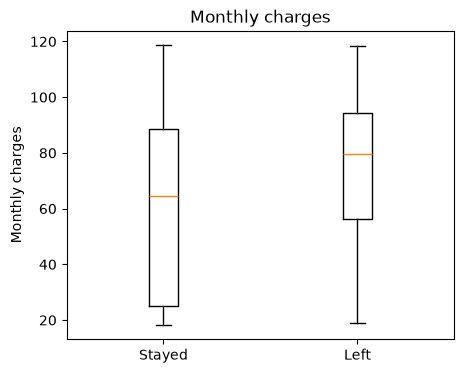

Average monthly charge (stayed): 61.27
Average monthly charge (left):   74.44


In [7]:
stayed = df[df["Churn"] == "No"]["MonthlyCharges"]
left = df[df["Churn"] == "Yes"]["MonthlyCharges"]

plt.figure(figsize=(5, 4))
plt.boxplot([stayed, left], tick_labels=["Stayed", "Left"])
plt.title("Monthly charges")
plt.ylabel("Monthly charges")
plt.savefig("outputs/monthly_charges_box.png", bbox_inches="tight")
plt.show()

print("Average monthly charge (stayed):", round(stayed.mean(), 2))
print("Average monthly charge (left):  ", round(left.mean(), 2))

Customers who left were paying more per month on average (74.44 compared to 61.27), so price may be one reason for leaving.

## 4. Handle missing values

First I check with `isnull()`.

In [8]:
print("Missing values found by isnull():", df.isnull().sum().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Missing values found by isnull(): 0
TotalCharges data type: str


`isnull()` finds nothing, but `TotalCharges` should be a number and pandas has read it as text. This means some values are not real numbers. Those cells contain a blank space, and pandas does not count a space as missing.

`pd.to_numeric` with `errors="coerce"` converts the column and turns anything it cannot read into `NaN`, so now we can find them.

In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

missing_rows = df[df["TotalCharges"].isnull()]
print("Missing TotalCharges:", len(missing_rows))
print("Median of TotalCharges:", df["TotalCharges"].median())
missing_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing TotalCharges: 11
Median of TotalCharges: 1397.475


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


The options are to fill with the mean, fill with the median, or drop the rows. All of these customers have a tenure of 0, so they joined just now and have not been billed yet. Filling with the median would give a brand new customer a bill they never paid, which is wrong. They are also a very small part of the data, so I **drop these rows**.

In [10]:
df = df.dropna(subset=["TotalCharges"])
print("Rows left:", len(df))
print("Missing values now:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows left: 7032
Missing values now: 0
Duplicate rows: 0


## 5. Encode categorical variables

Models only work with numbers, so text columns must be converted.

- `customerID` is removed because it is only a name for the row and tells us nothing about behaviour.
- **Label encoding** for columns with two values (No = 0, Yes = 1).
- **One-hot encoding** for columns with more than two values. Each category gets its own 0/1 column. I do not use label encoding here because 0, 1, 2 would tell the model that the categories have an order, and they do not. `drop_first=True` removes one column because it can be worked out from the others.

In [11]:
df = df.drop(columns=["customerID"])

# label encoding for columns with two values
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["gender"] = df["gender"].map({"Female": 0, "Male": 1})

for column in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    df[column] = df[column].map({"No": 0, "Yes": 1})

# one-hot encoding for the rest
text_columns = df.select_dtypes(exclude="number").columns.tolist()
print("One-hot encoding:", text_columns)

df = pd.get_dummies(df, columns=text_columns, drop_first=True, dtype=int)

print("New shape:", df.shape)
df.head()

One-hot encoding: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
New shape: (7032, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


### Correlation

Now that everything is a number I can check how the main columns relate to churn. Values near +1 or -1 mean a strong relation, and values near 0 mean a weak one.

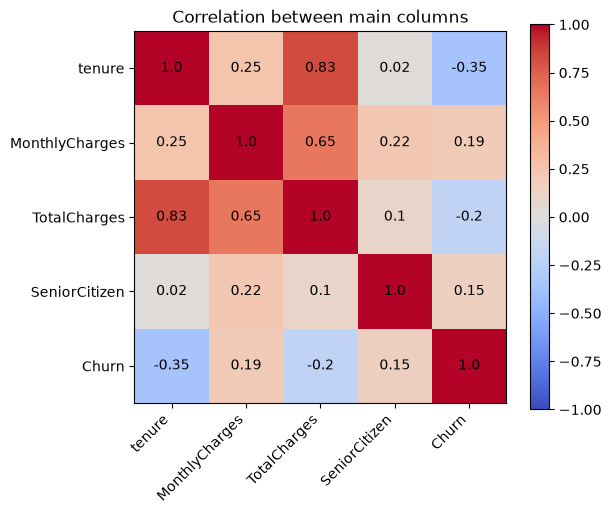

In [12]:
corr_columns = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
corr = df[corr_columns].corr()

plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr_columns)), corr_columns, rotation=45, ha="right")
plt.yticks(range(len(corr_columns)), corr_columns)

for i in range(len(corr_columns)):
    for j in range(len(corr_columns)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")

plt.title("Correlation between main columns")
plt.savefig("outputs/correlation.png", bbox_inches="tight")
plt.show()

`tenure` has the strongest relation with churn (-0.35): the longer a customer stays, the less likely they are to leave. `TotalCharges` and `tenure` are strongly related to each other (0.83), which makes sense because total charges grow every month. This overlap matters again in section 10.

## 6. Split the data and scale the numbers

**Train/test split:** 80% of the customers are used to train and 20% are kept hidden for the final test. `stratify=y` keeps the same churn percentage in both parts.

**Scaling:** `tenure` is at most 72 but `TotalCharges` goes into the thousands. KNN measures distance, so without scaling `TotalCharges` would decide almost everything. `StandardScaler` gives each column a mean of 0 and a standard deviation of 1.

The scaler is fitted on the training data only and then applied to the test data. If it saw the test data it would be a small form of cheating, called **data leakage**.

In [13]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

number_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

X_train = X_train.astype(float)
X_test = X_test.astype(float)

scaler = StandardScaler()
X_train[number_columns] = scaler.fit_transform(X_train[number_columns])
X_test[number_columns] = scaler.transform(X_test[number_columns])

print("Training customers:", X_train.shape[0])
print("Testing customers: ", X_test.shape[0])
print("Churn rate in train:", round(y_train.mean() * 100, 2))
print("Churn rate in test: ", round(y_test.mean() * 100, 2))

Training customers: 5625
Testing customers:  1407
Churn rate in train: 26.58
Churn rate in test:  26.58


## 7. Train the models

### Logistic Regression

It calculates a probability between 0 and 1 for each customer using the sigmoid function. If the probability is 0.5 or more, the customer is predicted as churn.

In [14]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### K-Nearest Neighbours (KNN)

KNN looks at the K most similar customers and takes a majority vote. So I have to choose K.

I must not pick K using the test set, or the test would no longer be a fair exam. Instead I use **5-fold cross validation** on the training data: it is split into 5 parts, and each part takes a turn as a small test. I score with F1 because of the imbalance. Only odd values are used so a vote cannot tie.

Best K: 35


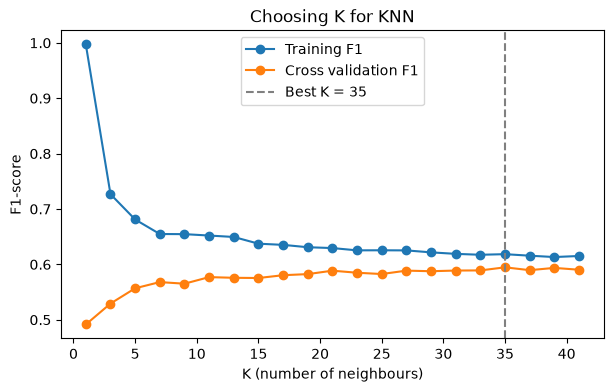

In [15]:
k_values = list(range(1, 42, 2))
train_scores = []
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    train_scores.append(f1_score(y_train, knn.predict(X_train)))
    cv_scores.append(cross_val_score(knn, X_train, y_train, cv=5, scoring="f1").mean())

best_k = k_values[int(np.argmax(cv_scores))]
print("Best K:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, train_scores, marker="o", label="Training F1")
plt.plot(k_values, cv_scores, marker="o", label="Cross validation F1")
plt.axvline(best_k, color="gray", linestyle="--", label="Best K = " + str(best_k))
plt.title("Choosing K for KNN")
plt.xlabel("K (number of neighbours)")
plt.ylabel("F1-score")
plt.legend()
plt.savefig("outputs/knn_choose_k.png", bbox_inches="tight")
plt.show()

The cross validation score was highest at K=35, but the line is almost flat after about K=20, so any K in that area would give similar results. At K=1 the training score is almost perfect while the cross validation score is the lowest. That is overfitting, which I look at in section 9.

In [16]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",35
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 8. Compare the models

What each measure means, where churn is the positive class:

- **Accuracy:** out of all customers, how many were predicted correctly.
- **Precision:** out of the customers we said will churn, how many really did. Low precision wastes offers on happy customers.
- **Recall:** out of the customers who really churned, how many we found. Low recall means losing customers without noticing.
- **F1-score:** a balance of precision and recall.

I also add a **baseline**: a fake model that always says "No churn". A real model must beat this to be useful.

In [17]:
def get_scores(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
    }


log_reg_pred = log_reg.predict(X_test)
knn_pred = knn.predict(X_test)
baseline_pred = np.zeros(len(y_test), dtype=int)

results = pd.DataFrame([
    get_scores("Baseline (always No)", y_test, baseline_pred),
    get_scores("Logistic Regression", y_test, log_reg_pred),
    get_scores("KNN (K=" + str(best_k) + ")", y_test, knn_pred),
])

results.round(3).to_csv("outputs/evaluation_summary.csv", index=False)
results.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline (always No),0.734,0.000,0.000,0.000
1,Logistic Regression,0.805,0.650,0.572,0.609
2,KNN (K=35),0.797,0.626,0.586,0.605


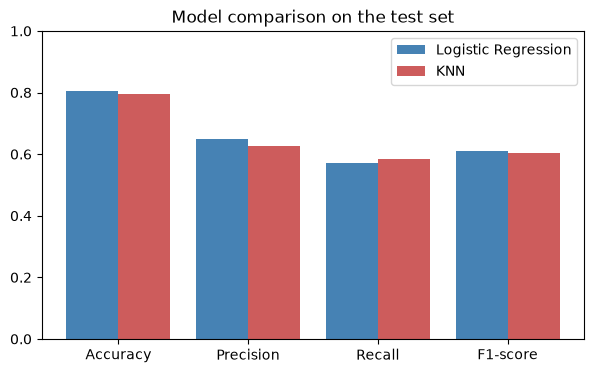

In [18]:
score_names = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(score_names))

plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, results.iloc[1][score_names].astype(float), width=0.4, label="Logistic Regression", color="steelblue")
plt.bar(x + 0.2, results.iloc[2][score_names].astype(float), width=0.4, label="KNN", color="indianred")
plt.xticks(x, score_names)
plt.ylim(0, 1)
plt.title("Model comparison on the test set")
plt.legend()
plt.savefig("outputs/model_comparison.png", bbox_inches="tight")
plt.show()

Both models beat the baseline accuracy of 73.4%, and the baseline finds no churners at all, which is why its recall and F1 are 0. This shows why accuracy alone is not enough. The two models are very close: Logistic Regression is slightly ahead on accuracy, precision and F1, and KNN is slightly ahead on recall.

### Confusion matrix

It shows the four possible outcomes. The top right cell is **false positives** (we said churn, but they stayed). The bottom left cell is **false negatives** (we said stay, but they left). For this problem false negatives cost more, because that customer is lost with no chance to keep them.

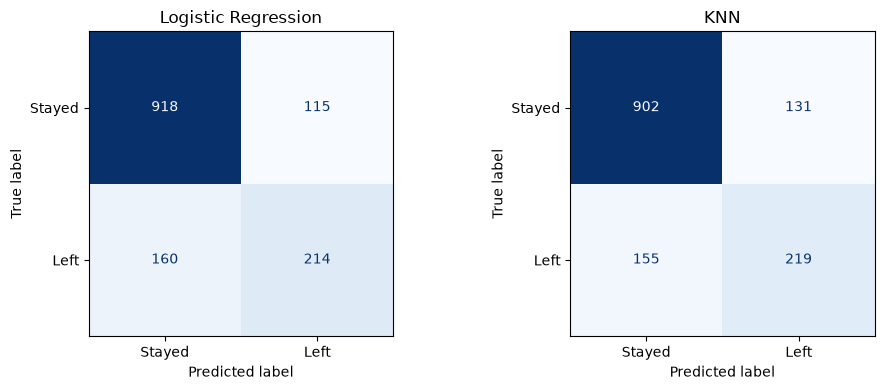

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, name in zip(axes, [log_reg_pred, knn_pred], ["Logistic Regression", "KNN"]):
    matrix = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(matrix, display_labels=["Stayed", "Left"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png", bbox_inches="tight")
plt.show()

There were 374 churners in the test set. Logistic Regression found 214 of them with 115 false alarms. KNN found 219 with 131 false alarms. So KNN found 5 more churners but gave 16 more false alarms.

## 9. Overfitting vs underfitting

**Overfitting:** the model memorises the training data, including its noise. The training score is high but the test score is much lower. It is like a student who memorised past papers and fails when the questions change.

**Underfitting:** the model is too simple to learn the pattern, so both scores are low. It is like a student who did not study.

A good model sits between these, with both scores close together and as high as possible.

KNN shows both clearly, because K controls how simple the model is. With K=1 each training customer is its own nearest neighbour, so the model has basically memorised the training data. With K=3001 the vote covers more than half of all training customers. The training set has only 1,495 churners, so churn can never get the 1,501 votes it needs, and the model says "No" for everyone.

In [20]:
rows = []

for name, model in [
    ("Logistic Regression", log_reg),
    ("KNN (K=1)", KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)),
    ("KNN (K=" + str(best_k) + ")", knn),
    ("KNN (K=3001)", KNeighborsClassifier(n_neighbors=3001).fit(X_train, y_train)),
]:
    train_f1 = f1_score(y_train, model.predict(X_train))
    test_f1 = f1_score(y_test, model.predict(X_test))
    rows.append({"Model": name, "Train F1": train_f1, "Test F1": test_f1, "Gap": train_f1 - test_f1})

fit_table = pd.DataFrame(rows).round(3)
fit_table.to_csv("outputs/overfitting_check.csv", index=False)
fit_table

,Model,Train F1,Test F1,Gap
0,Logistic Regression,0.600,0.609,-0.009
1,KNN (K=1),0.997,0.519,0.478
2,KNN (K=35),0.618,0.605,0.013
3,KNN (K=3001),0.000,0.000,0.000


- **KNN (K=1) is overfitting:** training F1 is 0.997 but test F1 is only 0.519, a gap of 0.478.
- **KNN (K=3001) is underfitting:** F1 is 0 on both, the same as the baseline.
- **KNN (K=35) and Logistic Regression are a good fit:** training and test scores are close, so they will work on new customers about as well as on the training data. The small negative gap for Logistic Regression just means the test set happened to be slightly easier.

## 10. Which columns push the prediction?

Logistic Regression gives each column a weight. A positive weight pushes the prediction towards churn and a negative weight pushes it towards staying.

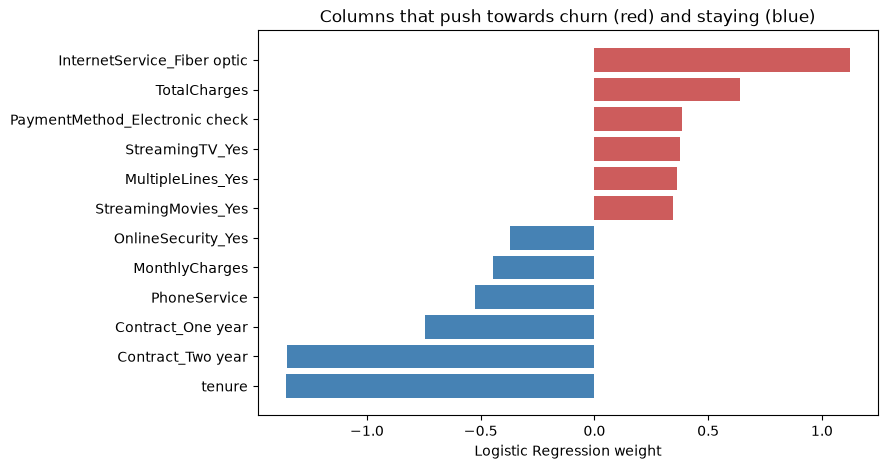

In [21]:
weights = pd.Series(log_reg.coef_[0], index=X_train.columns).sort_values()
top_weights = pd.concat([weights.head(6), weights.tail(6)])

plt.figure(figsize=(8, 5))
colors = ["steelblue" if w < 0 else "indianred" for w in top_weights]
plt.barh(top_weights.index, top_weights.values, color=colors)
plt.title("Columns that push towards churn (red) and staying (blue)")
plt.xlabel("Logistic Regression weight")
plt.savefig("outputs/churn_drivers.png", bbox_inches="tight")
plt.show()

Tenure and longer contracts push most strongly towards staying, and fiber optic internet pushes most strongly towards churn. This agrees with the EDA.

**A warning about these weights:** they show what the model uses, not what causes churn. `MonthlyCharges` has a negative weight here, even though the EDA showed that customers who left paid more. This is because the columns overlap. Monthly charges are mostly decided by the services a customer has, such as fiber optic, and `TotalCharges` is close to tenure multiplied by monthly charges. The model shares the effect between these columns, so one column's sign on its own can be misleading.
